# 11. (a) nonlinear-model MRAC + linear damper

**EXPLORATORY / offline / PROXY.** Reduced taut Newton-Euler model, development PC, **cable at the vehicle centre of mass (`d = 0`)** (Javier, 2026-11-25).

This notebook is a tutorial: every symbol, sign, matrix and cancellation is written out. Running all cells reads cached results of protocol 08 (defined under Terms below) and evaluates closed forms. The *live* panel at the end runs one short episode, and only when you press its button.

**Terms used in this notebook** (the full glossary is `00_Notation_and_Reading_Guide.ipynb`).
- **MQP** is the thesis derivation note *MRAC for a planar quadrotor with a cable-suspended payload* (`.ai/research/derivations/mrac-quadrotor-payload.md` in the thesis repository). Its status is PROPOSED, not accepted. Sections are cited as "MQP §x (section name)". This notebook carries the key steps itself, so you do not need to open the note.
- **EQ-MR-23** is the registry ID of the nonlinear-model MRAC law of extension (a) in the thesis equation registry (`.ai/research/equation-registry.md`). EQ-MR-22, the registry ID of the vanilla law of NB10, is the law this one extends.
- **Extensions (a), (b), (c).** (a) is the nonlinear-model law written in cable-frame channels (MQP §6.15). (b) adds disturbance-estimator weights on known radial basis functions. (c) adds $\sigma$-modification leaks (MQP §6.15.7). NB11 is (a), NB12 is (a)+(b), NB13 is (a)+(b)+(c).
- **Protocol 08** is the pre-registered protocol for these extension runs, approved by Javier on 2026-11-25 (`08_extensions_protocol.md` in the thesis repository's local, untracked `.ai/work/2026-11-25-mrac-vanilla/` folder). **AM1** is its amendment 1: the adaptation gain $\gamma_u$ was fixed by a preflight screen before any protocol data were produced (Section 7).

| Source | Where |
|---|---|
| Notation (residual.tex ↔ MQP ↔ code ↔ Guha) | thesis `.ai/research/derivations/notation-residual-tex.md`; reading guide `00_Notation_and_Reading_Guide.ipynb` |
| Derivation | MQP §6.15, "Nonlinear-model MRAC: local two-input extension with Guha's scalar-effectiveness pattern per cable-frame channel" (law EQ-MR-23) |
| Code | `experiments/mrac/vanilla_nl_mrac.py`; runner `mrac_lab/extensions_runs.py`; panels `mrac_lab/ext_panels.py` |
| Protocol | protocol 08 (approved 2026-11-25), amendment AM1 (gains fixed before data; see Terms) |
| Preceding notebook | NB10: vanilla MRAC on the linear outer model (EQ-MR-22) |

*Cached runs:* this notebook reads local run folders `results/mrac_*`, which are not in Git. On a fresh clone the first cell that needs one stops with a message naming `RESULTS_REGEN.md`, which lists the command that produced each folder; only folders whose receipt says `completed` are used.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from mrac_lab import provenance, ext_panels, blockdiag
prov = provenance.setup(modules=("experiments.mrac.vanilla_nl_mrac",))
provenance.banner(prov, "Extension series (protocol 08)", notes=("d = 0 (cable at the vehicle CoG)",
                  "Proved: derivative identity only; local convergence conditional (MQP 6.15.5)"))
RES = Path("results")
from mrac_lab import results as _results

def latest(stage):
    """Newest completed run folder of a stage; a completed composite (completion parts combined, AM3) first."""
    return _results.latest_completed(f"mrac_ext_{stage}", results=RES)

Extension series (protocol 08)
Label: EXPLORATORY / offline / PROXY (development PC, reduced taut point-load model)
Thesis checkout: <thesis> (machine path redacted 2026-11-27)
Commit: 10f3e8fc92de8f90be001601b6a4fbb5be88d0e7 (branch Claude, clean for experiments/mrac, experiments/notebook_utils/style.py, gym_pymunk_quadrotor)
Python: 3.12.3
Claim limits: No stability claim, no Pymunk-transfer claim, no hardware claim. Offline metrics are named *_off and are not the canonical c_T / c_S.
import origin: experiments.mrac.vanilla_nl_mrac -> <thesis>/experiments/mrac/vanilla_nl_mrac.py
Note: d = 0 (cable at the vehicle CoG)
Note: Proved: derivative identity only; local convergence conditional (MQP 6.15.5)


## 1. Notation (residual.tex is primary)

| Symbol | Meaning |
|---|---|
| $\{W\}$, $e_1, e_2$ | world frame, $z$ up, gravity $-g e_2$ |
| $m_q, J_q$ | vehicle mass and pitch inertia |
| $m_b$, $\ell$ | payload mass and rope length (fixed length, inextensible) |
| $M = m_q + m_b$ | total mass |
| $r_q, v_q$, $\theta_q, \omega_q$ | vehicle position, velocity, pitch, rate |
| $u = [f_q, \tau_q]^\top$ | thrust and torque |
| $F = f_q[-\sin\theta_q, \cos\theta_q]^\top$ | the thrust as a world force (the MRAC's virtual input) |
| $\varphi = \mathrm{atan2}(y_q - y_b, z_q - z_b)$ | rope angle (residual.tex) |
| $\hat u = [\sin\varphi, \cos\varphi]^\top$ | rope direction, load to vehicle |
| $\hat q = -\hat u$ | vehicle to load |
| $\hat t = [\cos\varphi, -\sin\varphi]^\top$ | tangent |
| $T^\varphi$ | tension |
| $\mathscr D = [d_{q,y}, d_{q,z}, d_{q,\tau}, d_\varphi]^\top$ | disturbances |
| $x^d$ | **task** state (residual.tex calls it "reference state") |
| $x_r$ | **reference model** (Guha): the nominal vehicle + 4 kg / 2 m payload flown by PID+FF + linear damper |
| $x$ | the real plant |
| $e = x - x_r$ | tracking error |

**Sign map** (code ↔ thesis, valid at $d = 0$): $\varphi_{\rm tex} = -\varphi_{\rm code}$, $\hat q = q_{\rm code}$, $\hat t = t_{\rm code}$.
- Plots show $\varphi_{\rm code}$ and say so.
- Odd functions of $\varphi$ flip sign; $\cos\varphi$, $T^\varphi$, $\hat t$ and $\hat q\hat q^\top$ do not.

**Dimensions** (stated once, used below). $r_q,v_q,F,w\in\mathbb R^2$ (components $(y,z)$); $x,x_r,e\in\mathbb R^6$ in the order $(y_q,v_{q,y},z_q,v_{q,z},\varphi,\dot\varphi)$ as in NB10; $R(\varphi)=[\hat t\ \hat q]\in\mathbb R^{2\times2}$ (rotation to the cable frame); $B_e(\varphi)\in\mathbb R^{6\times2}$; $D=\mathrm{diag}(1/m_q,1/M)$; $P,Q\in\mathbb R^{6\times6}$. The gains $\hat k_t,\hat k_u,\hat k_\varphi$ and the adaptation rates $\gamma_t,\gamma_u,\gamma_\varphi$ are scalars. The glossary and the residual.tex / code / Guha map are in `00_Notation_and_Reading_Guide.ipynb`.

## 2. Signal flow (block diagram)

> **Where this comes from.**
> - **Source:** MQP §6.15.3 (reference, error and nominal force) and §6.15.4 (law, EQ-MR-23); code `nl_command`, `run_nl` and `nl_advance` in `experiments/mrac/vanilla_nl_mrac.py`.
> - **Prerequisites:** NB10 Sections 3 and 4.
> - **Assumptions:**
>   1. The diagram and the steps below describe the sampled code (50 Hz, period $T_s=0.02$ s). Sections 3 to 6 derive its continuous idealisation.
>   2. The controller uses the nominal rope length $\ell_r=2$ m everywhere, also in the conditions where the plant length differs.

- **Σ symbols** carry their signs.
- **Dashed blocks** are features that are off in this notebook's variant.
- **Real plant:** the only block whose parameters ($m_q, J_q, m_b, \ell$) the controller does not know.
- **Reference model:** a simulation of the nominal system, run alongside the real plant.

**Signals the diagram does not draw** (their wires are left out to keep it readable):
- the rope angle $\varphi$ and rate $\dot\varphi$ into the cable-frame block (they set $R(\varphi)$ and $\xi_u$), and $\varphi$ into the law block ($F=Rw$) and into the adaptive law ($B_e(\varphi)$);
- the regressors $\xi_t,\xi_u,\Phi_\varphi$ into the adaptive law;
- the vehicle velocity $v$ into the RBF (radial basis function) block (that block is off here);
- the vehicle attitude $\theta_q$ and rate $\omega_q$ into the attitude PD;
- the reference damper torque from the reference loop into the cascade block (the block text names it);
- the cable tension of the reference vehicle, which the payload feedforward of the reference PID+FF uses.

**One control tick, in order** (all signals are read at the start of the tick).
1. **Reference command.** PID+FF (PID control plus payload feedforward) with the damper, evaluated on the reference state, gives a thrust $f_{\rm cmd}$ and a tilt command $\theta_{d,r}$. The code forms $u_r=f_{\rm cmd}\,[-\sin\theta_{d,r},\ \cos\theta_{d,r}]^\top-M_rge_2$.
2. **Error and nominal force.** $e=x-x_r$ (plant minus reference), then $F_n=u_r+M_rge_2-K_e^\top e$.
3. **Regressors** at the measured $\varphi,\dot\varphi$: $\xi_t=\hat t^\top F_n$, $\xi_u=\hat q^\top F_n+m_{b,r}\ell_r\dot\varphi^2$, $\Phi_\varphi=-\ell_r\dot\varphi^2$.
4. **Law.** $w_t=\hat k_t\xi_t$, $w_u=\hat k_u\xi_u+\hat k_\varphi\Phi_\varphi$ and $F=\hat t\,w_t+\hat q\,w_u=R(\varphi)w$.
5. **Cascade.** $f_q=\|F\|$; $\theta_d=\mathrm{atan2}(-F_y,F_z)$ clipped to $\pm0.6$ rad; $\omega_d=(\theta_d-\theta_{d,{\rm old}})/T_s$; $\tau_q=\mathrm{clip}\big(-J(k_{p,\theta}(\theta_q-\theta_d)+k_{d,\theta}(\omega_q-\omega_d)),\pm\tau_{max}\big)+\tau_{{\rm damper},r}$, with the attitude gains and $J$ of NB10 Section 3.1.
6. **Plant and reference step.** The allocation turns $(f_q,\tau_q)$ into motor commands and the plant is stepped, including the motor lag. The reference is stepped with its own command. Disturbances act on the plant only.
7. **Update** (explicit Euler; used from the next tick). Put $g=e^\top PB_e(\varphi)\in\mathbb R^{1\times2}$ and $\mathrm{reg}=(\xi_tg_t,\ \xi_ug_u,\ \Phi_\varphi g_u)$:
$$\hat k^+=\mathrm{clip}\big(\hat k-T_s\,\Gamma\,\mathrm{reg}-T_s\,\sigma(\hat k-k_0)\big),\qquad\Gamma=\mathrm{diag}(\gamma_t,\gamma_u,\gamma_\varphi)=\mathrm{diag}(0.0078,\,0.03,\,0.37),$$
with $\sigma=0$ in this variant, $k_0=(1,1,m_{b,r})$ and the boxes $\hat k_t\in[0.5,1.6]$, $\hat k_u\in[0.4,1.6]$, $\hat k_\varphi\in[0,12]$.

**About the clip.** Each gain box contains the ideals $(m_q/m_{q,r},\ M/M_r,\ m_b)$ of the protocol-08 conditions (a change of cable length has no exact ideal). Clipping a number onto an interval that contains $k^*$ never moves it further from $k^*$, so the clip never increases the weighted sum $\sum(\hat k_i-k_i^*)^2/c_i$ for positive weights $c_i$. This says nothing about the rest of the sampled step: no discrete Lyapunov decrease follows.

**Intuition.** Each tick compares the vehicle with the nominal one, turns the nominal command into the cable frame, rescales each channel with its adaptive gain, hands the force to the same attitude loop the baseline uses, and then moves the gains according to the error.

**What this does not show.** This is a description of the code path. It proves nothing about the sampled loop.

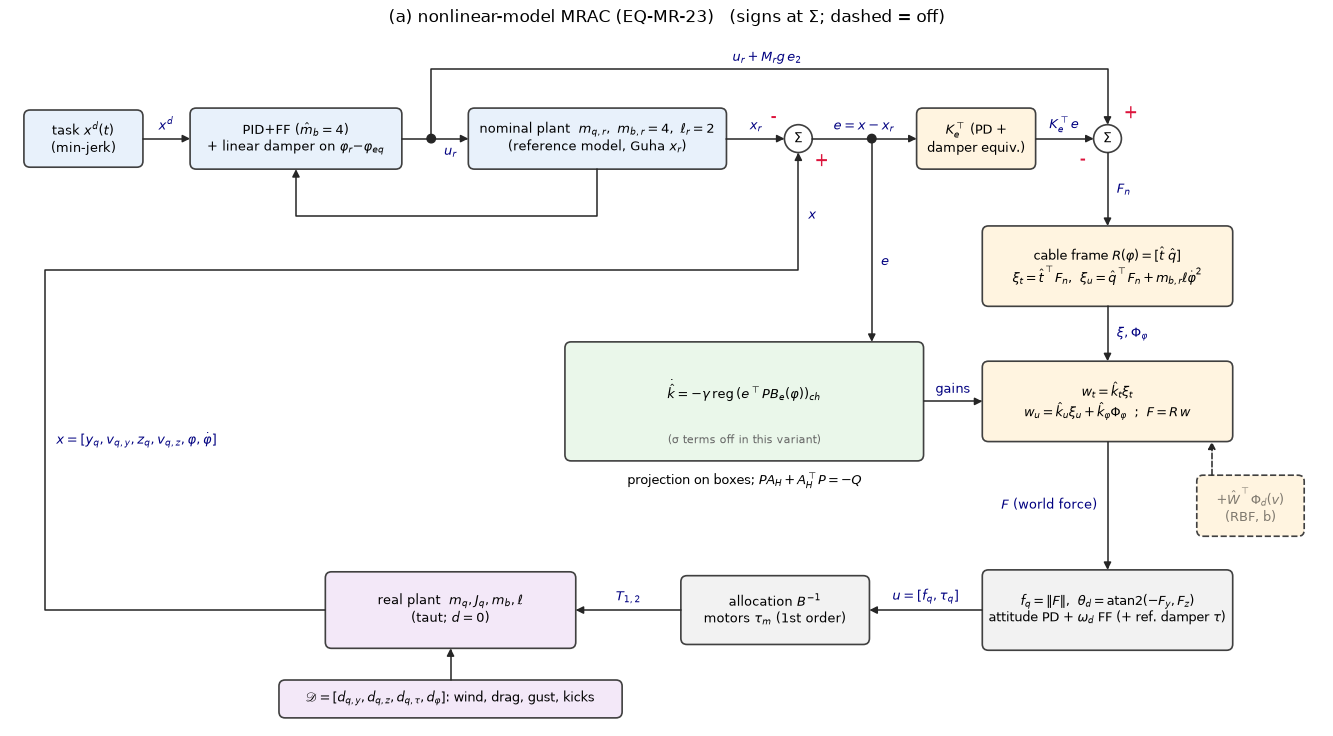

In [2]:
blockdiag.draw_vanilla_extensions("a"); plt.show()

## 3. The plant, derived step by step ($d = 0$)

> **Where this comes from.**
> - **Source:** MQP §6.15.1 ("Exact taut model at $d=0$"). Its two projections reproduce residual.tex eqs. (T_hybrid) and (phi_ddot_nl). The same model with an attachment offset is derived in NB05; here it is restricted to $d=0$.
> - **Prerequisites:** NB05 (Newton-Euler for the vehicle and the payload, the tension and swing projections); NB10 Section 2.1 (the same model linearized at hover).
> - **Assumptions:**
>   1. The rope is taut ($T^\varphi\ge 0$), massless and inextensible, with length $\ell$.
>   2. The payload is a point mass attached at the vehicle centre of mass ($d=0$), so the vehicle attitude does not enter.
>   3. The world force $F$ is the input (ideal inner loop).
>   4. No disturbances in this derivation.

**Step 0: geometry.** With $\hat q=[-\sin\varphi,-\cos\varphi]^\top$ and $\hat t=[\cos\varphi,-\sin\varphi]^\top$ we have $\hat q^\top\hat t=0$, $\hat q^\top\hat q=\hat t^\top\hat t=1$, $\hat q_z=-\cos\varphi$, $\hat t_z=-\sin\varphi$, and the derivatives $\partial\hat q/\partial\varphi=[-\cos\varphi,\sin\varphi]^\top=-\hat t$ and $\partial\hat t/\partial\varphi=[-\sin\varphi,-\cos\varphi]^\top=\hat q$.

**Step 1: Newton for both bodies.** The tension $T^\varphi\ge 0$ pulls the vehicle toward the load (along $\hat q$) and the load toward the vehicle:
$$m_q\ddot r_q = F - m_q g e_2 + T^\varphi\hat q,\qquad m_b\ddot r_b = -T^\varphi\hat q - m_b g e_2,\qquad r_b = r_q + \ell\hat q .$$

**Step 2: the constraint.** Differentiate $r_b = r_q + \ell\hat q(\varphi)$ twice; the rope length is fixed. First $\dot r_b=\dot r_q+\ell\dot\varphi\,\partial\hat q/\partial\varphi=\dot r_q-\ell\dot\varphi\hat t$. Again, with Step 0, $\ddot r_b=\ddot r_q-\ell\ddot\varphi\,\hat t-\ell\dot\varphi^2\hat q$. With $\hat q^\top \partial\hat q/\partial\varphi = 0$, the radial part of the load acceleration is $\hat q^\top\ddot r_b = \hat q^\top\ddot r_q - \ell\dot\varphi^2$ (the centripetal term), and the tangential part is $\hat t^\top\ddot r_b=\hat t^\top\ddot r_q-\ell\ddot\varphi$.

**Step 3: eliminate the tension.** Project the load equation on $\hat q$ (use $\hat q^\top\hat q=1$ and $\hat q^\top e_2=\hat q_z$): $m_b(\hat q^\top\ddot r_q-\ell\dot\varphi^2)=-T^\varphi-m_bg\hat q_z$. Solving for $T^\varphi$,
$$T^\varphi = m_b\big(\ell\dot\varphi^2 - g\hat q_z - \hat q^\top\ddot r_q\big) = m_b\big(g\cos\varphi + \hat u^\top\ddot r_q + \ell\dot\varphi^2\big),$$
which is exactly residual.tex eq. (T_hybrid) (with $\hat u=-\hat q$). The tangential projection ($\hat t^\top\hat q=0$, $\hat t^\top e_2=\hat t_z=-\sin\varphi$) gives $m_b(\hat t^\top\ddot r_q-\ell\ddot\varphi)=m_bg\sin\varphi$, which is the swing equation, residual.tex eq. (phi_ddot_nl):
$$\ell\ddot\varphi = -g\sin\varphi + \hat t^\top\ddot r_q .$$

**Step 4: substitute back.** Insert $T^\varphi$ into the vehicle equation. With the projectors $P_u = \hat q\hat q^\top$ (radial) and $P_t = \hat t\hat t^\top = I - P_u$ (tangential):
$$\underbrace{(m_q I + m_b P_u)}_{\tilde M(\varphi)}\ddot r_q = F - m_q g e_2 + m_b(\ell\dot\varphi^2 - g\hat q_z)\hat q .$$

$\tilde M = m_q P_t + M P_u$ is the **effective mass**:
- radially, the vehicle drags the whole payload, so the mass is $M$;
- tangentially, the payload swings freely, so the mass is $m_q$.

Its inverse is $\tilde M^{-1} = P_t/m_q + P_u/M$, because the projectors are orthogonal. Gravity collapses to $-g e_2$ in both channels. Write it out: $\tilde M^{-1}(-m_qge_2)=-gP_te_2-\frac{m_q}{M}gP_ue_2$, and, since $\hat q_z\hat q=P_ue_2$, $\tilde M^{-1}(-m_bg\hat q_z\hat q)=-\frac{m_b}{M}gP_ue_2$. Adding, with $\frac{m_q+m_b}{M}=1$ and $P_t+P_u=I$, gives $-gP_te_2-gP_ue_2=-ge_2$. The centripetal term lies along $\hat q$, so $\tilde M^{-1}$ divides it by $M$. Result:
$$\boxed{\ddot r_q = \tilde M^{-1}F - g e_2 + \frac{m_b}{M}\ell\dot\varphi^2\,\hat q}$$

This is a Lagrangian elimination in generalized coordinates (not a Hamiltonian form). Below, the closed form is checked against the simulator.

**Intuition.** Seen from the vehicle, the payload is a mass that is heavy along the cable (the vehicle must drag it) and invisible across it (the load swings freely), plus a centripetal pull toward the load when it swings fast. That is exactly what the effective mass $\tilde M$ and the last term encode.

In [3]:
import dataclasses, math
from experiments.mrac.baselines import canonical_offline_params
from experiments.mrac.quad_load_pend import PayloadParams, QuadLoadPend
from experiments.mrac.vanilla_nl_mrac import cable_frame_accel
canon = canonical_offline_params(); rng = np.random.default_rng(0); worst = 0.0
for _ in range(10):
    mq, mb, l = 9.6 * rng.uniform(.8, 1.2), rng.uniform(2, 6), rng.uniform(1.5, 2.5)
    plant = QuadLoadPend(dataclasses.replace(canon.quad, m=mq), PayloadParams(mb, l, 0.0))
    st = canon.with_condition(m_L=mb, cable_length=l).hover_state(theta=rng.uniform(-.3, .3), phi=rng.uniform(-.5, .5), phi_dot=rng.uniform(-1, 1))
    f, _ = plant.wrench(st.quad.c_L, st.quad.c_R)
    F = f * np.array([-math.sin(st.quad.theta), math.cos(st.quad.theta)])
    worst = max(worst, np.abs(cable_frame_accel(F, st.phi, st.phi_dot, m_q=mq, m_b=mb, l=l, g=9.81) - np.array(plant.accelerations(st).p_ddot)).max())
print(f"closed form vs simulator, 10 random taut states: max |difference| = {worst:.1e} m/s^2")

closed form vs simulator, 10 random taut states: max |difference| = 2.2e-15 m/s^2


## 4. Why the cable frame: one scalar effectiveness per channel

> **Where this comes from.**
> - **Source:** MQP §6.15.2 ("Cable-frame channels: one positive scalar effectiveness per channel"). The structure is Guha and Annaswamy's scalar effectiveness $\lambda$ (arXiv 2011.10562, eqs. 4 and 7): the plant input is $\lambda B_ru$ with an unknown positive scalar $\lambda$ of known sign.
> - **Prerequisites:** NB04 (Guha's scalar-$\lambda$ class); NB10 Section 2.2 (where the diagonal $\Lambda$ came from); Section 3 above.
> - **Assumptions:** (1) the rotation $R(\varphi)$ is known, because $\varphi$ is measured; (2) matched cable length, $\ell=\ell_r$; (3) $d=0$.

Write the world force in the cable frame, $F = R(\varphi)w$ with $R = [\hat t\ \hat q]$. The rotation is known, because $\varphi$ is measured. Then
$$\hat t^\top\ddot r_q = \frac{w_t}{m_q} - g\hat t_z,\qquad \hat q^\top\ddot r_q = \frac{w_u}{M} - g\hat q_z + \frac{m_b}{M}\ell\dot\varphi^2 .$$
To see this, note that $R^\top R=I$ gives $\hat t^\top F=w_t$ and $\hat q^\top F=w_u$. Apply $\hat t^\top$ and $\hat q^\top$ to the boxed result of Section 3: $\hat t^\top P_t=\hat t^\top$ and $\hat t^\top P_u=0$, so $\hat t^\top\tilde M^{-1}=\hat t^\top/m_q$; likewise $\hat q^\top\tilde M^{-1}=\hat q^\top/M$. Gravity gives $-g\hat t_z$ and $-g\hat q_z$, and $\hat t^\top\hat q=0$ removes the centripetal term from the $t$ channel.

Each channel has **one positive scalar effectiveness**, unknown in value but known in sign. This is the structure of Guha's $\lambda$:
$$\lambda_t = m_{q,r}/m_q,\qquad \lambda_u = M_r/M .$$

**Why the cable frame?** A single world-frame scalar $\lambda$ would need $m_b/m_q = m_{b,r}/m_{q,r}$, i.e. proportional masses (finding N4 of the independent Codex design review). Indeed, $\tilde M^{-1}=\lambda\tilde M_r^{-1}$ requires $1/m_q=\lambda/m_{q,r}$ and $1/M=\lambda/M_r$; eliminating $\lambda$ gives $m_q/m_{q,r}=M/M_r$, that is $1+m_b/m_q=1+m_{b,r}/m_{q,r}$. The cable frame removes that condition.

**Scope.** The two channels share one state through $B_e(\varphi)$. So this is a **local two-input extension using Guha's scalar-effectiveness and adaptive-law pattern channelwise**. MQP §6.15 proves its Lyapunov derivative identity only; local convergence is conditional on premises that are not discharged there. Guha's theorem itself is not imported.

**Intuition.** Along the cable the vehicle is "heavy" ($M$), across it the vehicle is "light" ($m_q$), and each direction has its own unknown mass ratio. Giving each direction its own adaptive scalar matches the physics. A single gain in world axes would force the unknown ratios of the two directions to be equal.

## 5. Law, ideal gains and the nominal identity

> **Where this comes from.**
> - **Source:** MQP §6.15.3 ("Reference, error and the nominal force") and §6.15.4 ("Law", EQ-MR-23).
> - **Prerequisites:** NB10 Sections 3 and 4 (reference, error feedback $K_e$, the law of the vanilla case); Sections 3 and 4 above.
> - **Assumptions:** (1) matched cable length $\ell=\ell_r$ and $d=0$; (2) the reference is the nominal vehicle with the nominal 4 kg / 2 m payload, flown by PID+FF plus the linear damper; (3) the regressors use the measured $\varphi$, $\dot\varphi$ and the reference signals.

**Nominal command.** The vanilla error path (NB10) gives the nominal world force: the PD+FF+damper action on $e = x - x_r$,
$$F_n = u_r + M_r g e_2 - K_e^\top e .$$
Here $u_r$ is the reference policy's gravity-offset command (called $\nu_r$ in NB10), so $F_n=\xi+M_rg\,e_2$, with $\xi=u_r-K_e^\top e$ the corrected command of NB10.

**Target acceleration.** The nominal model's acceleration at the plant's own angle is the boxed formula of Section 3 with the reference parameters and the force $F_n$:
$$a_d=\tilde M_r^{-1}F_n-ge_2+\frac{m_{b,r}}{M_r}\ell\dot\varphi^2\hat q .$$
The law is built so that the real plant accelerates as $\ddot r_q=a_d$.

**Regressors.**
$$\xi_t = \hat t^\top F_n,\qquad \xi_u = \hat q^\top F_n + m_{b,r}\ell\dot\varphi^2,\qquad \Phi_\varphi = -\ell\dot\varphi^2 .$$

**Law.**
$$w_t = \hat k_t\,\xi_t,\qquad w_u = \hat k_u\,\xi_u + \hat k_\varphi\,\Phi_\varphi,\qquad F = R(\varphi)\,w .$$

**Ideal gains.** $k_t^* = m_q/m_{q,r} = 1/\lambda_t$, $k_u^* = M/M_r = 1/\lambda_u$, $k_\varphi^* = m_b$.

**Check that the ideals reproduce $a_d$.**
- $t$ channel: $\hat t^\top\ddot r_q=\dfrac{w_t^*}{m_q}-g\hat t_z=\dfrac{(m_q/m_{q,r})\,\hat t^\top F_n}{m_q}-g\hat t_z=\dfrac{\hat t^\top F_n}{m_{q,r}}-g\hat t_z=\hat t^\top a_d$, because $\hat t^\top\tilde M_r^{-1}=\hat t^\top/m_{q,r}$ and $\hat t^\top\hat q=0$.
- $u$ channel: $w_u^*=\dfrac M{M_r}\big(\hat q^\top F_n+m_{b,r}\ell\dot\varphi^2\big)-m_b\ell\dot\varphi^2$, so
$$\frac{w_u^*}{M}+\frac{m_b}{M}\ell\dot\varphi^2=\frac{\hat q^\top F_n+m_{b,r}\ell\dot\varphi^2}{M_r}=\frac{\hat q^\top F_n}{M_r}+\frac{m_{b,r}}{M_r}\ell\dot\varphi^2 ,$$
the two $m_b\ell\dot\varphi^2/M$ terms cancelling. Subtracting $g\hat q_z$ gives $\hat q^\top a_d$.

**Which terms cancel.** With the ideals, $w_u^*/M + (m_b/M)\ell\dot\varphi^2 = \hat q^\top F_n/M_r + (m_{b,r}/M_r)\ell\dot\varphi^2$. The real payload's centripetal pull is removed and the nominal one restored, so the plant accelerates exactly as the nominal model would under $F_n$.

**Nominal identity.** At the nominal gains $(1, 1, m_{b,r})$, $w = R^\top F_n$, so $F = F_n$. A nominal plant therefore reproduces the reference exactly (checked: $\|e\| < 10^{-10}$). Indeed $w_t=\xi_t=\hat t^\top F_n$ and $w_u=\xi_u+m_{b,r}\Phi_\varphi=\hat q^\top F_n$, and $RR^\top=I$.

**Intuition.** The law reads the nominal command, resolves it along and across the cable, and rescales each part by an unknown mass ratio so that the real vehicle accelerates like the nominal one. A third term removes the real payload's centripetal pull and the regressor $\xi_u$ puts the nominal one back.

## 6. Error equation and Lyapunov function, line by line

> **Where this comes from.**
> - **Source:** MQP §6.15.5 ("Error equation and Lyapunov function", the pattern of Guha's Thm. 3: storage $\lambda\tilde k^2/\gamma$ per channel).
> - **Prerequisites:** NB10 Sections 3 and 4 (the error $e$, $A_H$, the Lyapunov equation, the cancellation of the cross term); Sections 3 to 5 of this notebook.
> - **Assumptions:**
>   1. $d=0$ and $\ell=\ell_r$; $m_q$ and $m_b$ are unknown constants; the ideal gains $k^*$ are constant.
>   2. The force $F$ is realized exactly: continuous time, no projection, no saturation, ideal inner loop.
>   3. $P=P^\top>0$ solves $PA_H+A_H^\top P=-Q$ with $Q=Q^\top>0$ and $A_H=A_r-B_rK_e^\top$ from NB10.
>   4. $\gamma_t,\gamma_u,\gamma_\varphi>0$.

**0. Deviation of the real plant from the nominal model.** Write $w=w^*+\tilde w$ with $\tilde w=(\tilde k_t\xi_t,\ \tilde k_u\xi_u+\tilde k_\varphi\Phi_\varphi)$ and $\tilde k=\hat k-k^*$. The cable-frame equations of Section 4 are affine in $w$ and the ideal $w^*$ gives $\ddot r_q=a_d$ (Section 5), so
$$\ddot r_q=a_d+\frac{\tilde w_t}{m_q}\hat t+\frac{\tilde w_u}{M}\hat q=a_d+R(\varphi)D\tilde w,\qquad D=\mathrm{diag}(1/m_q,\,1/M).$$
In the swing equation $\ell\ddot\varphi=-g\sin\varphi+\hat t^\top\ddot r_q$ only the $t$ part enters, because $\hat t^\top\hat q=0$: the extra swing acceleration is $\tilde w_t/(m_q\ell)$. In the state order $(y_q,v_{q,y},z_q,v_{q,z},\varphi,\dot\varphi)$ this is
$$\dot x=f_{\rm nom}(x,F_n)+B_e(\varphi)D\tilde w,\qquad B_e(\varphi)=\begin{bmatrix}0&0\\ \hat t_y&\hat q_y\\ 0&0\\ \hat t_z&\hat q_z\\ 0&0\\ 1/\ell&0\end{bmatrix}\in\mathbb R^{6\times2},$$
where $f_{\rm nom}(x,F)$ is the nominal model (reference parameters, Section 3 equations) evaluated at the plant state. The $+1/\ell$ in the $\dot\varphi$ row is in residual.tex $\varphi$ ($-1/\ell$ in the code's $\varphi$). The reference runs on its own force $F_r=u_r+M_rge_2$: $\dot x_r=f_{\rm nom}(x_r,F_r)$.

**1. Error dynamics.** With ideal gains the plant follows the nominal model evaluated at the plant state. Subtract the reference: $\dot e=f_{\rm nom}(x,F_n)-f_{\rm nom}(x_r,F_r)+B_eD\tilde w$. At hover $f_{\rm nom}(x,F)\approx A_rx+B_r(F-M_rge_2)$, and $F_n-F_r=-K_e^\top e$, so the difference is $A_re-B_rK_e^\top e=A_He$ plus a remainder $N$ that collects everything beyond this linear expression. Let $\tilde w = (\tilde k_t\xi_t,\ \tilde k_u\xi_u + \tilde k_\varphi\Phi_\varphi)$ and $D = \mathrm{diag}(1/m_q, 1/M)$. Then
$$\dot e = A_H e + N(x, x_r) + B_e(\varphi)\,D\,\tilde w,$$
where:
- $A_H = A_r - B_r K_e^\top$ is Hurwitz (NB10 §3);
- $N$ is the known kinematic remainder of the linearization. It is defined by $N=f_{\rm nom}(x,F_n)-f_{\rm nom}(x_r,F_r)-A_He$: second order in $e$ plus the variation of the Jacobian along the trajectory. It can be computed from $x,x_r$, but nothing in this notebook bounds it;
- $B_e(\varphi)$ places a unit channel acceleration in the error rows: velocity along $\hat t$ or $\hat q$, and $\pm 1/\ell$ in the $\dot\varphi$ row for the $t$ channel.

**2. Storage.** As in Guha's $\lambda\tilde k^2/\gamma$, with the unknown positive $1/m_q$ and $1/M$ in the role of $\lambda$:
$$V = e^\top Pe + \frac{\tilde k_t^2}{m_q\gamma_t} + \frac{\tilde k_u^2}{M\gamma_u} + \frac{\tilde k_\varphi^2}{M\gamma_\varphi},\qquad PA_H + A_H^\top P = -Q .$$
$V>0$ unless $e=0$ and $\tilde k=0$.

**3. Differentiate.** $P$ is symmetric and the ideal gains are constant ($\dot{\tilde k}=\dot{\hat k}$):
$$\dot V=e^\top(PA_H+A_H^\top P)e+2e^\top PN+2e^\top PB_eD\tilde w+\frac{2\tilde k_t\dot{\hat k}_t}{m_q\gamma_t}+\frac{2\tilde k_u\dot{\hat k}_u}{M\gamma_u}+\frac{2\tilde k_\varphi\dot{\hat k}_\varphi}{M\gamma_\varphi}.$$
The first term is $-e^\top Qe$. Since $D$ is diagonal and $e^\top PB_e\in\mathbb R^{1\times2}$ (subscripts $t,u$ pick its two entries), the cross term is
$$2e^\top PB_eD\tilde w=2(e^\top PB_e)_t\frac{\tilde k_t\xi_t}{m_q}+2(e^\top PB_e)_u\frac{\tilde k_u\xi_u+\tilde k_\varphi\Phi_\varphi}{M}.$$
Assembled:
$$\dot V = -e^\top Qe + 2e^\top PN + 2(e^\top PB_e)_t\frac{\tilde k_t\xi_t}{m_q} + 2(e^\top PB_e)_u\frac{\tilde k_u\xi_u + \tilde k_\varphi\Phi_\varphi}{M} + \frac{2\tilde k_t\dot{\hat k}_t}{m_q\gamma_t} + \frac{2\tilde k_u\dot{\hat k}_u}{M\gamma_u} + \frac{2\tilde k_\varphi\dot{\hat k}_\varphi}{M\gamma_\varphi}.$$

**4. Choose the updates** so that each cross term cancels its storage term. The unknown $1/m_q$ and $1/M$ factor out, so they are never needed:
$$\dot{\hat k}_t = -\gamma_t\xi_t(e^\top PB_e)_t,\qquad \dot{\hat k}_u = -\gamma_u\xi_u(e^\top PB_e)_u,\qquad \dot{\hat k}_\varphi = -\gamma_\varphi\Phi_\varphi(e^\top PB_e)_u .$$
Substituting: $\frac{2\tilde k_t\dot{\hat k}_t}{m_q\gamma_t}=-\frac{2\tilde k_t\xi_t(e^\top PB_e)_t}{m_q}$ cancels the $t$ cross term; $\frac{2\tilde k_u\dot{\hat k}_u}{M\gamma_u}=-\frac{2\tilde k_u\xi_u(e^\top PB_e)_u}{M}$ and $\frac{2\tilde k_\varphi\dot{\hat k}_\varphi}{M\gamma_\varphi}=-\frac{2\tilde k_\varphi\Phi_\varphi(e^\top PB_e)_u}{M}$ cancel the two pieces of the $u$ cross term.

**Intuition.** This is the same cancellation as in NB10, now channel by channel in the cable frame: each unknown mass ratio enters through one channel, so one adaptive scalar per channel (plus the centripetal gain) removes it. What is left, $2e^\top PN$, is the price of using a nonlinear model with a linear error equation: nothing here controls its size.

**5. Result.** $\dot V = -e^\top Qe + 2e^\top PN(x, x_r)$.
- **Proved:** this identity, i.e. the exact cancellation of the parametric uncertainty.
- **Not proved:** convergence. That needs a bound on $N$ near the trajectory, an invariant region inside the taut domain, and regularity (MQP §6.15.5).
- **Not part of the calculation:** the sampled loop, the projection, the motor lag and the inner attitude loop. They are checked numerically below.

## 7. Before running: the sampled loop is checked locally (per-stage preflight)

> **Where this comes from.**
> - **Source:** MQP §6.14.8 (method) and §6.15.6 ("Gains, fixed before the protocol-08 data"); code `nl_hover_jacobian` in `experiments/mrac/vanilla_nl_mrac.py` and `preflight` in `mrac_lab/extensions_runs.py`; the receipt of the stage (table of the next cell).
> - **Prerequisites:** NB10 Section 5 (the same method), Sections 3 to 6 here.
> - **Assumptions:**
>   1. One tick at taut hover for each of the 21 protocol conditions at $d=0$, with the reference at its own hover.
>   2. Gains at the plant's ideals (weights at zero); projection off and the gain leak $\sigma$ set to zero.
>   3. A local statement about the sampled loop at one operating point.

The proof is continuous-time; the real tick is sampled at 50 Hz with motor lag. The runner therefore checks every condition before any episode, using a finite-difference Jacobian of one real tick at hover with ideal gains.

**Step 1: the tick as a map.** $z_{k+1}=G(z_k)$, with $z$ made of the plant state (8), the two motor states, the stored tilt command $\theta_{d,{\rm old}}$, the three gains $\hat k$: $z\in\mathbb R^{14}$.

**Step 2: linearise.** $J$ is the central-difference Jacobian of $G$ at the hover point $z_0$, with step $10^{-6}\max(1,|z_{0,i}|)$ in entry $i$ (as in NB10 Section 5).

**Step 3: the directions that hover does not excite.** They are removed structurally, that is, written down from the formulas, not picked from eigenvalues.
- **$\hat k_t$.** At hover $F_n=(0,M_rg)^\top$ is vertical and $\hat t$ is horizontal, so $\xi_t=\hat t^\top F_n=0$. A change in $\hat k_t$ alters neither the force nor any update to first order: $J\varepsilon=\varepsilon$ ($\varepsilon$ the unit vector of that entry).
- **$\hat k_\varphi$.** $\Phi_\varphi=-\ell\dot\varphi^2$ and its derivative vanish at $\dot\varphi=0$, so again $J\varepsilon=\varepsilon$.

There are therefore 2 such directions (this variant has no weights).

**Step 4: the rest.** Let $S$ span those directions and $Q_R$ their orthogonal complement. $\rho$ is the largest modulus among the eigenvalues of $Q_R^\top JQ_R$, and the **growth rate** is $\ln\rho/T_s$ (1/s). When $S$ is invariant ($Q_R^\top JS=0$), these are the eigenvalues of $J$ that remain after removing the directions in $S$ (block triangular form, NB10 Section 5).

**Step 5: what the saved runs required.** The runner version that produced these results (tutorial commit `052a9ec`) required only a negative growth rate (also recorded in protocol 08, amendment AM4). All saved rates are $-0.35$ to $-0.29$ /s, so they are also below $-0.05$ /s. The current runner (protocol 08 AM5) additionally requires rate $\le-0.05$ /s and invariance residual $<10^{-6}$, and labels rows with drift above $10^{-9}$ *not a fixed point, not certified* instead of failing them: that is the motor-asymmetry rows `veh_delta=0.05` and `veh_delta=0.10` (drift 0.0088 and 0.0177); a rerun of the preflight function alone (2026-11-27) reproduces the saved rates and passes the other 19 rows. *Drift* is $\max|G(z_0)-z_0|$. Where it is not zero (motor asymmetry), hover with ideal gains is not a fixed point, so those rows are not a local-stability certificate. Earlier text listed weight directions here, although this variant has no weights, and did not state the drift.

**Choice of $\gamma_u$.** $\gamma_u=0.03$ was fixed by this screen, run for the law of extension (a), before any protocol data (protocol 08, amendment AM1). The rule: take the largest value in $\{0.0562,0.03,0.02,0.015,0.01\}$ for which all 21 protocol conditions at $d=0$ ($m_q$ and $J$ changes, arm length, motor asymmetry, $m_b$ from 2 to 6 kg, $\ell$ of 1.5 and 2.5 m) decay at $-0.05$ /s or faster. The result is 0.03, with worst case $-0.294$ /s (at 2 kg) in the screen receipt; the direct mapping $1000/(M_rg)^2=0.056$ grew at 2 kg ($+0.150$ /s). That mapping omits the channel-mass factor used for the other gains (with it, about $0.0041$; inferred, not screened); $\gamma_u$ was set by the screen. Earlier text gave a worst case of $-0.25$ /s and described the screened plants as $m_q$ from $0.7\times$ to $1.3\times$.

**What this does not show.** A negative rate is a local property of the linearised sampled tick at one operating point. It says nothing about large errors, manoeuvres or disturbances.

In [4]:
ST = latest("a")
print("stage folder:", ST)
rec = json.loads((ST / "receipt.json").read_text())
if "composite_of" in rec:  # completion parts combined (protocol 08 AM3)
    print("composite of:", [(p["folder"], p["status"], p.get("n_results")) for p in rec["composite_of"]])
    rec = rec["composite_of"][0]
print("status", rec["status"], "| wall", round(rec.get("wall_s", 0)), "s | thesis", rec["thesis_commit"][:7], "| dirty", rec["dirty_paths"])
display(pd.DataFrame(rec["preflight"]).T.round(4))

stage folder: results\mrac_ext_a_20261125T121348
status completed | wall 6549 s | thesis 57a3372 | dirty []


,rate_per_s,invariance,drift
veh_nominal,-0.3533,0.0,0.0000
veh_m_q-20%,-0.2981,0.0,0.0000
veh_m_q-10%,-0.3411,0.0,0.0000
veh_m_q+10%,-0.3480,0.0,0.0000
veh_m_q+20%,-0.3428,0.0,0.0000
veh_J-30%,-0.3533,0.0,0.0000
veh_J-15%,-0.3533,0.0,0.0000
veh_J+15%,-0.3533,0.0,0.0000
veh_J+30%,-0.3533,0.0,0.0000
veh_a_p-10%,-0.3533,0.0,0.0000


## 8. Results: grid over vehicle and payload mismatch (interactive)

> **Where this comes from.**
> - **Source:** the saved summaries of the protocol-08 stages loaded by the next cell; panel code `mrac_lab/ext_panels.py` (`grid_panel`); metrics from `summarise` in `mrac_lab/extensions_runs.py`.
> - **Prerequisites:** Sections 6 and 7; NB10 Section 7 (scenarios and disturbances).
> - **Assumptions and limits:**
>   1. Deterministic episodes of the reduced model, $d=0$ except the `robust` set.
>   2. The comparison is descriptive.

- **Rows:** conditions. These are the 15 vehicle-mismatch cases (mass, inertia, arm, motor asymmetry) at 4 kg / 2 m, plus payload mass and rope length.
- **Columns:** arms. This variant's ONLINE (adaptation on) and FROZEN (the same design with the estimates held fixed, no updates), TUNED'-online (code key `v0_online`, called V0 in protocol 08: the vanilla law of NB10 with the gains chosen under tuning protocol 06, adaptation on; in NB10's T2 tables the same key means a different design, G0-pre), and the PID+FF and softer-damper baselines.
- **Controls:** tick or untick arms, and choose the metric, scenario, disturbance and set.

**Sets** (`set` menu). Scenarios are `hover` (hold, starting with 0.35 rad of swing) and `transfer` (4 m in 4 s).
- `grid`: the 21 conditions, both scenarios, 120 s.
- `dist`: six representative conditions (`veh_nominal`, `mb6`, `mb2`, `l2.5`, `veh_m_q+20%`, `veh_delta=0.10`), eight disturbance cases (constant, Ornstein-Uhlenbeck with seeds 1 to 3, drag, gust, payload kick, vehicle kick), both scenarios.
- `long`: 600 s transfers with the ONLINE and FROZEN arms of a variant, five conditions.
- `robust`: $d=0.3795$ m, a readout only.
- The constant, Ornstein-Uhlenbeck, drag and gust cases are those of NB10 Section 7.4. A payload kick adds 0.5 rad/s to $\dot\varphi$ and a vehicle kick adds 0.5 m/s to $v_{q,y}$, both at 30 s and 60 s.

**Metrics** (`metric` menu). With $T$ the episode length and $(y,z)$ the vehicle position error from the task:
$$\texttt{task\_rms\_last60}=\sqrt{\operatorname{mean}_{t\in[T-60,T)}\,(y^2+z^2)}\quad[\mathrm m].$$
- `swing_rms_10_30`, `swing_rms_last60`: root mean square (RMS) of the swing angle (rad) over $[10,30)$ s and over the last 60 s.
- `ref_err_rms_last60`: the same RMS for the position part of $e=x-x_r$ (only arms that run against the reference model: ONLINE, FROZEN and TUNED'-online).
- `sat_frac`: fraction of ticks with a saturated motor.
- `kick0_swing_rms_5s`, `kick0_task_max_5s`: swing RMS and largest position error in the 5 s after the first kick. `kick0_settle_s`: time from the first kick to the last instant before the next kick with $|\varphi|>0.01$ rad (0 if there is none).

**Reading a cell.** Each cell is the mean of the metric over the episodes that match the row, the arm and the chosen scenario, disturbance and set; for Ornstein-Uhlenbeck wind that is the mean over three seeds. The title counts failed episodes. A failed episode has no value or a value from a truncated record.

**What this does not show.** A lower value in one cell is an observation about these deterministic episodes; the scored comparison is Section 10.

In [5]:
folders = [latest(s) for s in ['a']]
S = ext_panels.load_summaries(folders)  # latest() raises on a missing stage
ext_panels.grid_panel(S)

## 9. Episodes: (i) temporal, (ii) gain convergence, (iii) Lyapunov variables (interactive)

> **Where this comes from.**
> - **Source:** the episode CSV files of the stage folders (every 10th control tick, that is 5 Hz); panel code `mrac_lab/ext_panels.py` (`episode_panel`).
> - **Prerequisites:** Sections 6 to 8.
> - **Assumptions:** as in Section 8.

Choose a condition, scenario and disturbance, then toggle arms and plot groups.
- The `long` set holds the 600 s transfers, where the gains have longer to evolve (parameter convergence is not claimed).
- Kicks are at 30 s and 60 s; the red dotted lines mark them.

**What each plot group shows.**
- **(i) temporal:** the task error $\|r_q-r^d\|$ (m) and the swing angle in degrees, in code sign ($\varphi_{\rm tex}=-\varphi_{\rm code}$).
- **(ii) gains:** $\hat k_t$ (solid) and $\hat k_u$ (dashed) with black ideal lines, $\hat k_\varphi$ with its ideal, and, where weights exist, $\|\hat W_t\|,\|\hat W_u\|$ (dotted). The vanilla arm shows $\hat K_x[1,F_z]$ divided by its first value and $\hat K_x[\varphi,F_y]$. The ideal lines use the plant's true parameters and exist only for plotting.
- **(iii) Lyapunov:** $V_e=e^\top Pe$ and $\|e\|$ on a log scale ($10^{-16}$ added before taking the log). $V_e$ is only the state part of the storage of Section 6. The gain terms are not plotted: for the cable-frame arms the saved column `V_K` replaces the unknown channel scales $1/m_q,1/M$ by 1, so it is a diagnostic and not the gain part of $V$. Baselines have no $V_e$.

**Reading (iii).** The identity of Section 6 concerns the full $V$ (error and gain terms) in continuous time, and it keeps the term $2e^\top PN$. So $V_e$ may rise, and a falling $V_e$ in one episode is not a proof.

In [6]:
ext_panels.episode_panel(S)

## 10. Which statement improves which (protocol 08 §6 rule)

"X improves on Y in a disturbance class" when X has the lower task error in at least 75 % of the class's comparable paired cells, **and** the swing gate G3' is *True* for X there. G3' is protocol 06's swing gate: the swing RMS over 10 to 30 s must not exceed $\max(B_S,\,0.005\ \mathrm{rad})$, with $B_S$ the softer baseline's swing plus half of any excess of PID+FF over it. Unknown G3' never passes.
- **Both directions** are scored with each arm's own G3'.
- **A failed episode** makes its cell non-comparable; it never becomes the other arm's win.
- **Scored sets:** only the grid and disturbance sets. The 600 s holds and the `d = 0.3795` runs are readouts.
- **Nature of the test:** descriptive and deterministic (one run per cell, three OU seeds).
- **PE Gramian:** NOT MEASURED in this protocol run, so **no parameter-convergence claim** is made (finding EXT-05 of the independent Codex review of the extensions report).

In [7]:
from mrac_lab import ext_analysis
an_folders = folders
res = ext_analysis.compare(ext_analysis.load(an_folders))
rows = [dict(comparison=p, disturbance=d, comparable=v["comparable"], X_scores=v["x_scores"], X_improves=v["x_improves"],
             Y_scores=v["y_scores"], Y_improves=v["y_improves"], G3_unknown_X=v["g3_unknown_x"],
             failed_X=v["failed_x"], failed_Y=v["failed_y"], median_X=v["median_x"], median_Y=v["median_y"])
        for p, r in res.items() for d, v in r.items()]
display(pd.DataFrame(rows).round(5))
display(ext_analysis.kick_table(ext_analysis.load(an_folders)).round(4))

,comparison,disturbance,comparable,X_scores,X_improves,Y_scores,Y_improves,G3_unknown_X,failed_X,failed_Y,median_X,median_Y
0,a_online vs v0_online,D0 none,42,36,True,6,False,0,0,0,0.00000,0.00000
1,a_online vs v0_online,D1 constant,12,0,False,12,True,0,0,0,0.14238,0.00002
2,a_online vs v0_online,D3 drag,12,0,False,12,True,0,0,0,0.19807,0.00002
3,a_online vs v0_online,D4 gust,12,0,False,12,True,0,0,0,0.18848,0.11899
4,a_online vs v0_online,D2 OU,36,0,False,36,True,0,0,0,0.13281,0.04956
5,a_online vs v0_online,D5 payload kick,12,4,False,8,False,0,0,0,0.05289,0.05284
6,a_online vs v0_online,D6 vehicle kick,12,0,False,12,True,0,0,0,0.06314,0.05431
7,a_online vs a_frozen,D0 none,42,20,False,22,False,0,0,0,0.00000,0.00000
8,a_online vs a_frozen,D1 constant,12,12,True,0,False,0,0,0,0.14238,0.40896
9,a_online vs a_frozen,D3 drag,12,12,True,0,False,0,0,0,0.19807,0.44100


kick0_swing_rms_5s  kick0_task_max_5s  kick0_settle_s  \
dist         arm                                                                
payload_kick a_frozen               0.0585             0.5143            4.37   
             a_online               0.0579             0.3779            4.25   
             pidff                  0.0904             0.1491            7.01   
             softer                 0.0753             0.2832            5.84   
             v0_online              0.0627             0.3409            8.54   
vehicle_kick a_frozen               0.0299             0.5231            4.98   
             a_online               0.0299             0.3636            4.90   
             pidff                  0.0480             0.2276            6.13   
             softer                 0.0382             0.2469            4.93   
             v0_online              0.0407             0.2774            8.87   

                        kick1_settle_s  
dist         arm                        
payload_kick a_frozen             4.37  
             a_online             4.27  
             pidff                7.01  
             softer               5.84  
             v0_online            8.52  
vehicle_kick a_frozen             4.98  
             a_online             4.90  
             pidff                6.13  
             softer               4.93  
             v0_online            8.82

## 11. Live: tune the gains yourself (one short episode per button press)

In [8]:
ext_panels.live_panel("a")

## 12. Claim limits

- **Exact:** the cancellation of the parametric uncertainty in the derivative identity, for the continuous, unprojected force-input model at $d = 0$.
- **Not proved:** local convergence (premises listed in MQP §6.15.5, "Error equation and Lyapunov function").
- **Numerical evidence only:** the sampled loop, which is local and finite-horizon, on a single machine (PROXY).
- **Not claimed:**
  - parameter convergence without excitation ($\hat k_\varphi$ needs swing, $\hat k_t$ needs lateral force);
  - results for $d \ne 0$ (the `robust` set is a readout only);
  - Pymunk, hardware or multi-vehicle results.
- **Next:** Combining MRAC with a residual policy is planned for evaluation on the Pymunk plant, with no observation adapter (project master plan, item A6; a local planning document). Offline MRAC with the damper reference remains the theory and tuning vehicle. Nothing of that combination has been run. Any further step needs Javier's approval.